# Notebook 05r — Evaluasi Model (REVISI)
**Basis:** `05_evaluasi_model.ipynb` (tidak diubah).

**Apa yang direvisi dan mengapa:**
- **Baseline persistensi** ditambahkan ke tabel dan grafik (RF, XGBoost, LightGBM, Persistensi).
- **E3 – status WASPADA recall 0%.** Evaluasi status irigasi diulang dari prediksi 1 jam pada data uji revisi (2 node, tanpa kebocoran), lengkap dengan **jumlah sampel aktual per kelas (support)** agar kelas langka seperti JENUH dapat ditafsirkan. Ditambahkan **aturan peringatan dini** dan analisis **kejadian transisi** (waktu tenggang).
- **E2 – uji sensitivitas Node 3**: RF dengan best_params revisi dilatih ulang pada dataset 3 node.
- Semua angka dikumpulkan di `models/revisi/hasil_revisi_lengkap.json`.

In [1]:
# -- CELL 1: Import & load ----------------------------------------
import os, json, warnings, joblib
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             confusion_matrix, precision_recall_fscore_support, accuracy_score)
plt.style.use('seaborn-v0_8-whitegrid')

OUT, MOUT = 'dataset/revisi', 'models/revisi'
HORIZONS = ['60m', '180m', '360m']
MENIT = {'60m': 60, '180m': 180, '360m': 360}
MODELS = ['rf', 'xgb', 'lgb', 'pers']
LABEL = {'rf': 'Random Forest', 'xgb': 'XGBoost', 'lgb': 'LightGBM', 'pers': 'Persistensi'}
COLORS = {'rf': '#1565C0', 'xgb': '#43A047', 'lgb': '#FF6F00', 'pers': '#757575'}

with open(f'{MOUT}/rf_metrics_all.json') as f: rf_m = json.load(f)
with open(f'{MOUT}/xgb_metrics_all.json') as f: xgb_m = json.load(f)
with open(f'{MOUT}/lgb_metrics_all.json') as f: lgb_m = json.load(f)
MET = {'rf':  {h: rf_m[h]['test_metrics'] for h in HORIZONS},
       'xgb': {h: xgb_m[h]['test_metrics'] for h in HORIZONS},
       'lgb': {h: lgb_m[h]['test_metrics'] for h in HORIZONS},
       'pers': {h: rf_m[h]['persistensi_metrics'] for h in HORIZONS}}
HASIL = {}
def py(o):
    if isinstance(o, dict): return {str(k): py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [py(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return o

Horizon         Model  MAE(%)  RMSE(%)     R2  MAPE(%)
    60m Random Forest  1.6232   2.7665 0.9569     2.58
    60m       XGBoost  1.6188   2.9260 0.9518     2.61
    60m      LightGBM  1.9133   3.2146 0.9418     3.04
    60m   Persistensi  1.3807   2.9681 0.9504     2.27
   180m Random Forest  2.8007   4.1744 0.9029     4.49
   180m       XGBoost  3.4943   5.9204 0.8047     5.80
   180m      LightGBM  2.9369   4.8697 0.8678     4.82
   180m   Persistensi  2.2743   4.0822 0.9071     3.79
   360m Random Forest  3.5790   4.9054 0.8681     5.60
   360m       XGBoost  5.1333   6.7741 0.7484     8.02
   360m      LightGBM  5.2266   6.9582 0.7345     8.22
   360m   Persistensi  3.3341   5.2071 0.8513     5.67

Model terbaik per horizon (RMSE): {'60m': 'Random Forest', '180m': 'Random Forest', '360m': 'Random Forest'}
Selisih RMSE terhadap persistensi (%, negatif = lebih baik): {'60m': {'Random Forest': -6.79, 'XGBoost': -1.42, 'LightGBM': 8.31}, '180m': {'Random Forest': 2.26, 'XGBoost': 4

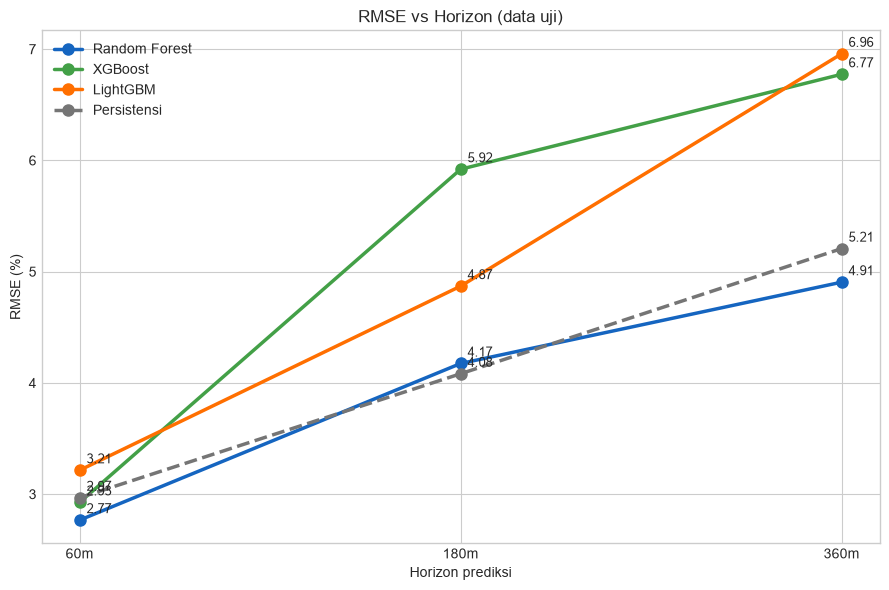

In [2]:
# -- CELL 2: Tabel perbandingan 4 model ---------------------------
rows = []
for h in HORIZONS:
    for m in MODELS:
        x = MET[m][h]
        rows.append({'Horizon': h, 'Model': LABEL[m], 'MAE(%)': round(x['MAE'], 4), 'RMSE(%)': round(x['RMSE'], 4),
                     'R2': round(x['R2'], 4), 'MAPE(%)': round(x['MAPE'], 2)})
df_comp = pd.DataFrame(rows)
print(df_comp.to_string(index=False))
df_comp.to_csv(f'{OUT}/ringkasan_evaluasi_revisi.csv', index=False)

BEST = {h: min(['rf', 'xgb', 'lgb'], key=lambda m: MET[m][h]['RMSE']) for h in HORIZONS}   # model terbaik (RMSE terendah, di luar persistensi)
print('\nModel terbaik per horizon (RMSE):', {h: LABEL[m] for h, m in BEST.items()})
HASIL['tabel_perbandingan'] = df_comp.to_dict(orient='records')
HASIL['model_terbaik_per_horizon'] = {h: LABEL[m] for h, m in BEST.items()}
HASIL['model_vs_persistensi_rmse_persen'] = {
    h: {LABEL[m]: round((MET[m][h]['RMSE']/MET['pers'][h]['RMSE'] - 1)*100, 2) for m in ['rf', 'xgb', 'lgb']} for h in HORIZONS}
print('Selisih RMSE terhadap persistensi (%, negatif = lebih baik):', HASIL['model_vs_persistensi_rmse_persen'])

fig, ax = plt.subplots(figsize=(9, 6))
for m in MODELS:
    v = [MET[m][h]['RMSE'] for h in HORIZONS]
    ax.plot(HORIZONS, v, 'o-', lw=2.5, ms=8, color=COLORS[m], label=LABEL[m], ls='--' if m == 'pers' else '-')
    for h, x in zip(HORIZONS, v): ax.annotate(f'{x:.2f}', (h, x), textcoords='offset points', xytext=(5, 5), fontsize=9)
ax.set_xlabel('Horizon prediksi'); ax.set_ylabel('RMSE (%)'); ax.set_title('RMSE vs Horizon (data uji)'); ax.legend()
plt.tight_layout(); plt.savefig(f'{OUT}/plot_rmse_vs_horizon_revisi.png', dpi=150); plt.show()

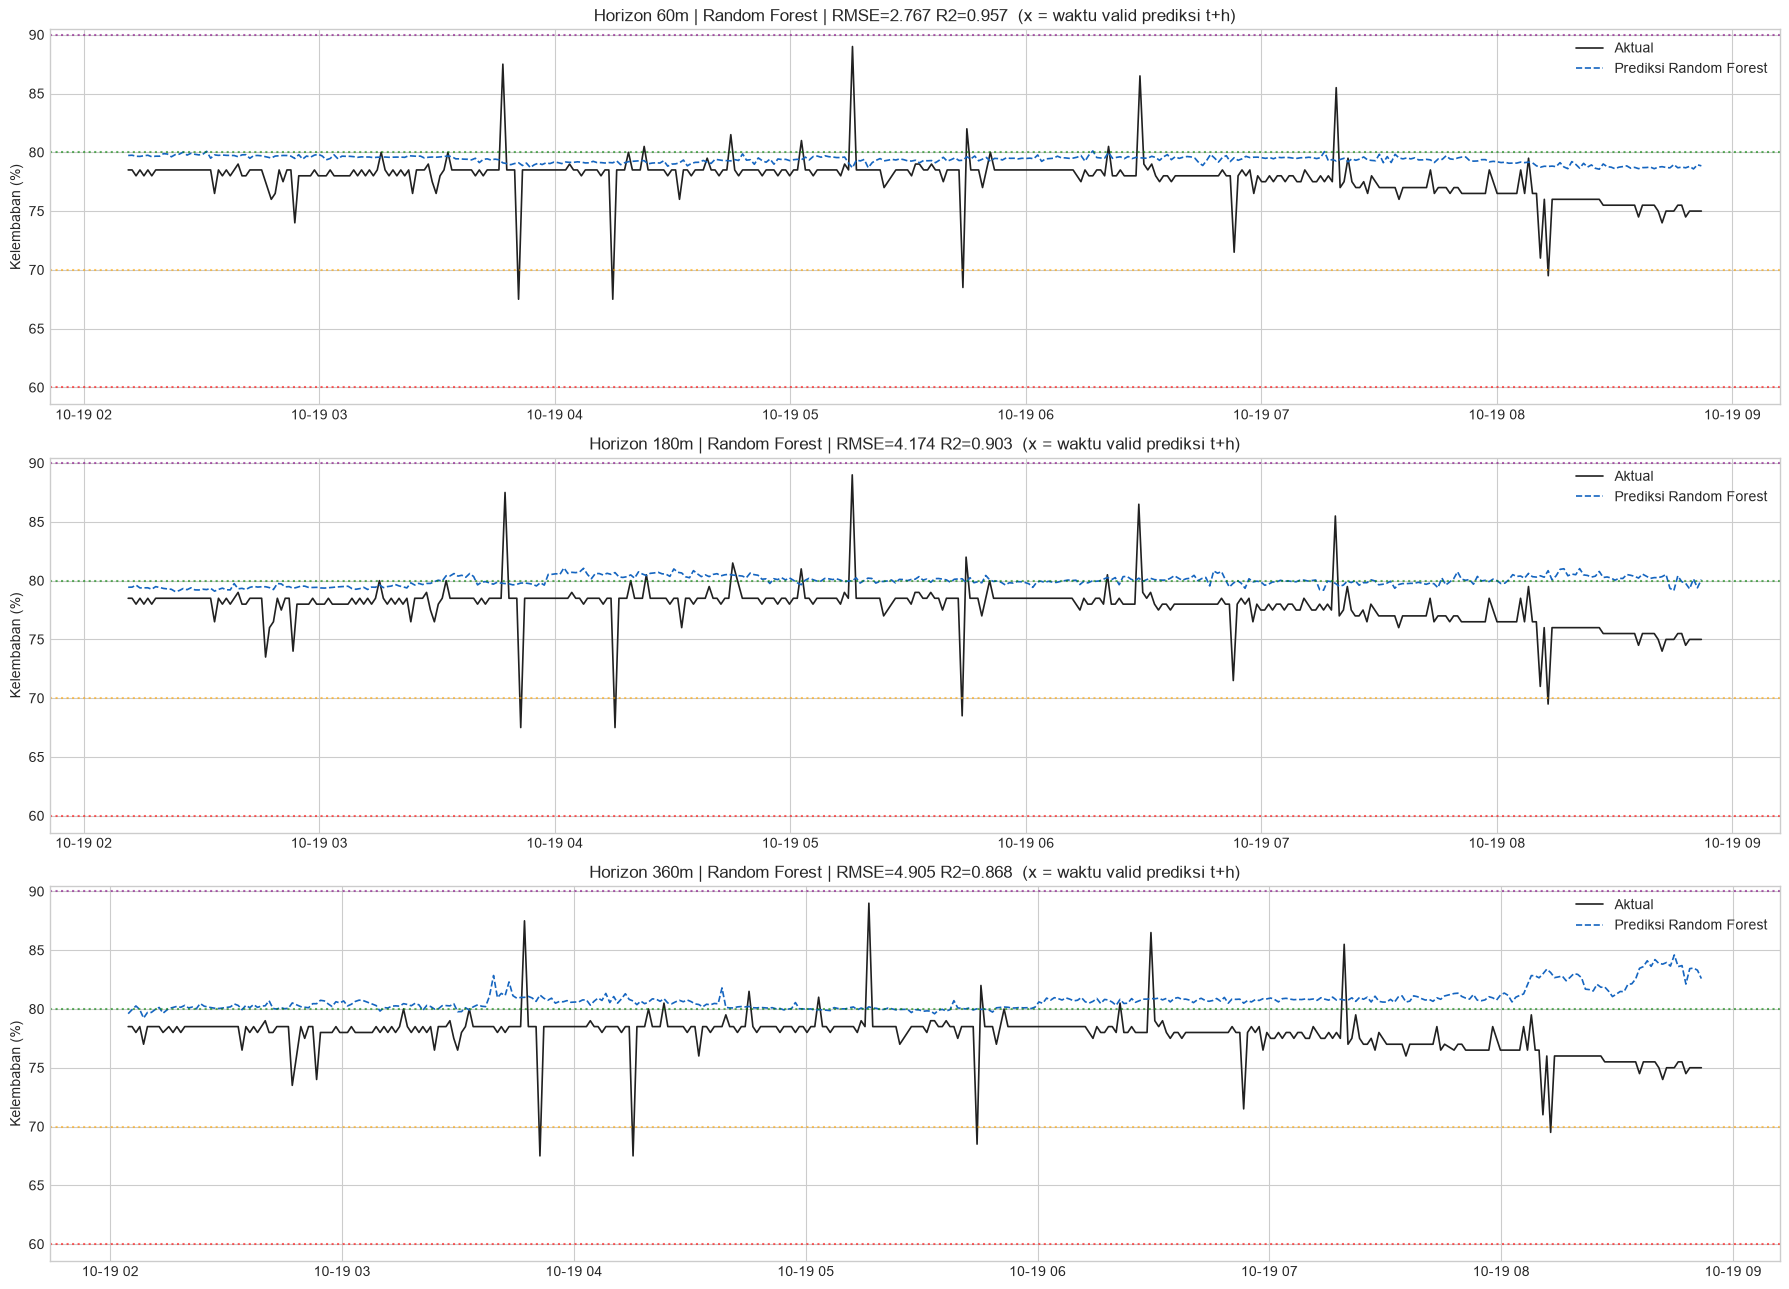

In [3]:
# -- CELL 3: Prediksi vs aktual (model terbaik), sumbu-x = t+h -----
PRED = {}
for h in HORIZONS:
    m = BEST[h]
    PRED[h] = pd.read_csv(f'{OUT}/prediksi_{m}_{h}.csv', parse_dates=['waktu_pembacaan'])
fig, axes = plt.subplots(3, 1, figsize=(18, 13))
for ax, h in zip(axes, HORIZONS):
    d = PRED[h].tail(400); m = BEST[h]
    wv = d['waktu_pembacaan'] + pd.Timedelta(minutes=MENIT[h])
    ax.plot(wv, d['aktual'], color='#212121', lw=1.2, label='Aktual')
    ax.plot(wv, d[f'prediksi_{m}'], color=COLORS[m], lw=1.2, ls='--', label=f'Prediksi {LABEL[m]}')
    for t_, c_ in [(60, 'red'), (70, 'orange'), (80, 'green'), (90, 'purple')]: ax.axhline(t_, color=c_, ls=':', alpha=0.6)
    ax.set_title(f'Horizon {h} | {LABEL[m]} | RMSE={MET[m][h]["RMSE"]:.3f} R2={MET[m][h]["R2"]:.3f}  (x = waktu valid prediksi t+h)')
    ax.set_ylabel('Kelembaban (%)'); ax.legend()
plt.tight_layout(); plt.savefig(f'{OUT}/plot_prediksi_multihorizon_revisi.png', dpi=150); plt.show()

Model 1 jam yang dipakai: Random Forest
Distribusi status AKTUAL (data uji):
KRITIS     6788
WASPADA    4928
OPTIMAL    7852
LEMBAB     1007
JENUH         8

=== ATURAN DASAR (status dari prediksi 1 jam) === akurasi = 88.14% (n=20,583)
                pred KRITIS  pred WASPADA  pred OPTIMAL  pred LEMBAB  \
aktual KRITIS          6751            29             8            0   
aktual WASPADA            9          3878          1037            4   
aktual OPTIMAL            5           361          6754          732   
aktual LEMBAB             2           120           127          758   
aktual JENUH              3             0             5            0   

                pred JENUH  
aktual KRITIS            0  
aktual WASPADA           0  
aktual OPTIMAL           0  
aktual LEMBAB            0  
aktual JENUH             0  
         precision  recall      f1  support_aktual  jumlah_diprediksi
KRITIS      0.9972  0.9945  0.9959            6788               6770
WASPADA     0.883

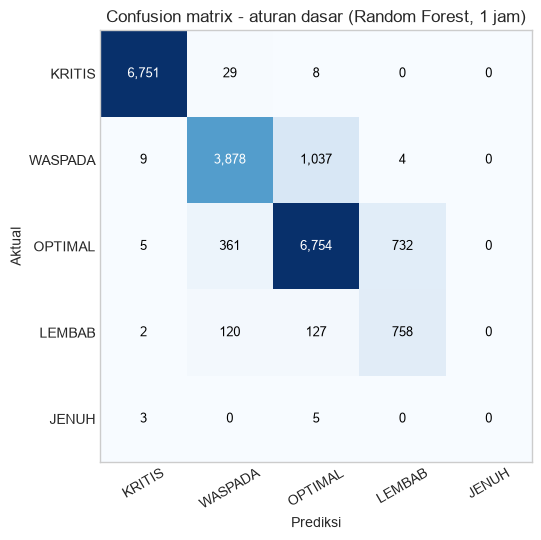

In [4]:
# -- CELL 4: Status irigasi dari prediksi 1 jam --------------------
KELAS = ['KRITIS', 'WASPADA', 'OPTIMAL', 'LEMBAB', 'JENUH']
def status(v):
    v = np.asarray(v, dtype=float)
    return np.select([v < 60, v < 70, v < 80, v < 90], KELAS[:4], default='JENUH')

def eval_status(y_true, y_pred, nama):
    cm = confusion_matrix(y_true, y_pred, labels=KELAS)
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=KELAS, zero_division=0)
    tab = pd.DataFrame({'precision': p, 'recall': r, 'f1': f, 'support_aktual': s,
                        'jumlah_diprediksi': cm.sum(axis=0)}, index=KELAS)
    acc = accuracy_score(y_true, y_pred)
    print(f'\n=== {nama} === akurasi = {acc*100:.2f}% (n={len(y_true):,})')
    print(pd.DataFrame(cm, index=[f'aktual {k}' for k in KELAS], columns=[f'pred {k}' for k in KELAS]))
    print(tab.round(4))
    return {'akurasi': float(acc), 'n': int(len(y_true)), 'confusion_matrix': cm.tolist(), 'labels': KELAS,
            'per_kelas': {k: {c: float(tab.loc[k, c]) for c in tab.columns} for k in KELAS}}, cm

def plot_cm(cm, judul, fn):
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(5)); ax.set_xticklabels(KELAS, rotation=30); ax.set_yticks(range(5)); ax.set_yticklabels(KELAS)
    for i in range(5):
        for j in range(5): ax.text(j, i, f'{cm[i,j]:,}', ha='center', va='center', color='white' if cm[i,j] > cm.max()/2 else 'black', fontsize=9)
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual'); ax.set_title(judul); ax.grid(False)
    plt.tight_layout(); plt.savefig(fn, dpi=150); plt.show()

m1 = BEST['60m']
d1 = PRED['60m']
st_aktual = status(d1['aktual']); st_dasar = status(d1[f'prediksi_{m1}'])
print('Model 1 jam yang dipakai:', LABEL[m1])
print('Distribusi status AKTUAL (data uji):'); print(pd.Series(st_aktual).value_counts().reindex(KELAS).fillna(0).astype(int).to_string())
res_dasar, cm_dasar = eval_status(st_aktual, st_dasar, 'ATURAN DASAR (status dari prediksi 1 jam)')
plot_cm(cm_dasar, f'Confusion matrix - aturan dasar ({LABEL[m1]}, 1 jam)', f'{OUT}/plot_confusion_dasar.png')
HASIL['status_irigasi_dasar'] = {'model': LABEL[m1], **res_dasar,
    'distribusi_aktual': pd.Series(st_aktual).value_counts().reindex(KELAS).fillna(0).astype(int).to_dict()}

Baris 1 jam: 20,583 -> baris gabungan 1/3/6 jam: 19,702 (6 jam terakhir tiap segmen tak punya target 6 jam)
Status dinaikkan menjadi WASPADA oleh aturan dini: 711 baris (3.61%)

=== ATURAN DASAR (baris gabungan yang sama) === akurasi = 87.71% (n=19,702)
                pred KRITIS  pred WASPADA  pred OPTIMAL  pred LEMBAB  \
aktual KRITIS          6468            28             8            0   
aktual WASPADA            9          3585          1033            4   
aktual OPTIMAL            5           358          6469          730   
aktual LEMBAB             2           120           117          758   
aktual JENUH              3             0             5            0   

                pred JENUH  
aktual KRITIS            0  
aktual WASPADA           0  
aktual OPTIMAL           0  
aktual LEMBAB            0  
aktual JENUH             0  
         precision  recall      f1  support_aktual  jumlah_diprediksi
KRITIS      0.9971  0.9945  0.9958            6504               6487

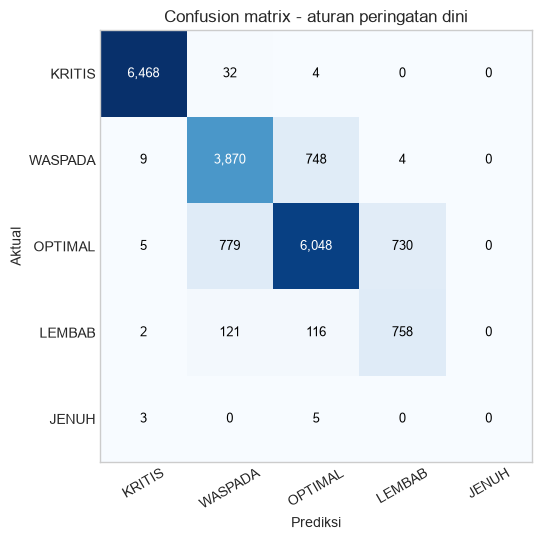

In [5]:
# -- CELL 5: Aturan peringatan dini -------------------------------
# WASPADA bila prediksi 1 jam >= 70 tetapi min(prediksi 3 jam, prediksi 6 jam) < 70 (digabung per waktu_pembacaan)
M = d1[['waktu_pembacaan', 'segmen', 'aktual', 'sekarang']].copy()
M['p1'] = d1[f'prediksi_{BEST["60m"]}'].values
for h, nm in [('180m', 'p3'), ('360m', 'p6')]:
    M = M.merge(PRED[h][['waktu_pembacaan', f'prediksi_{BEST[h]}']].rename(columns={f'prediksi_{BEST[h]}': nm}),
                on='waktu_pembacaan', how='inner')
M = M.sort_values('waktu_pembacaan').reset_index(drop=True)
print(f'Baris 1 jam: {len(d1):,} -> baris gabungan 1/3/6 jam: {len(M):,} (6 jam terakhir tiap segmen tak punya target 6 jam)')

M['st_aktual'] = status(M['aktual'])
M['st_dasar'] = status(M['p1'])
naik = (M['p1'] >= 70) & (np.minimum(M['p3'], M['p6']) < 70)
M['st_dini'] = np.where(naik, 'WASPADA', M['st_dasar'])
print(f'Status dinaikkan menjadi WASPADA oleh aturan dini: {int(naik.sum()):,} baris ({naik.mean()*100:.2f}%)')

res_dasar_M, _ = eval_status(M['st_aktual'], M['st_dasar'], 'ATURAN DASAR (baris gabungan yang sama)')
res_dini, cm_dini = eval_status(M['st_aktual'], M['st_dini'], 'ATURAN PERINGATAN DINI')
plot_cm(cm_dini, 'Confusion matrix - aturan peringatan dini', f'{OUT}/plot_confusion_dini.png')
HASIL['status_irigasi_dasar_baris_gabungan'] = res_dasar_M
HASIL['status_irigasi_peringatan_dini'] = {**res_dini, 'baris_dinaikkan_ke_waspada': int(naik.sum())}

In [6]:
# -- CELL 6: Kejadian transisi (sekarang turun melewati 70 / 60) ----
TAHAN, LOOKBACK, MAXLEAD = 30, 120, 360      # menit: bertahan di bawah ambang >= 30 menit ; jendela pencarian peringatan 120 menit sebelum transisi

def kejadian_turun(d, thr):
    ev = []
    for sid, g in d.groupby('segmen'):
        t = g['waktu_pembacaan'].values; v = g['sekarang'].values
        below = v < thr
        for i in np.where((~below[:-1]) & below[1:])[0] + 1:
            if (t[i] - t[i-1]) > np.timedelta64(2, 'm'): continue
            end = t[i] + np.timedelta64(TAHAN, 'm')
            if t[-1] < end: continue                       # segmen berakhir sebelum 30 menit
            w = (t >= t[i]) & (t <= end)
            if v[w].max() >= thr: continue                 # tidak bertahan di bawah ambang
            ev.append((sid, t[i]))
    return ev

def tenggang(d, ev, kolom_status, ok):
    # Peringatan harus AKTIF TERUS-MENERUS sampai baris terakhir sebelum transisi (celah <= 2 menit).
    # tenggang = waktu transisi - awal rangkaian peringatan aktif itu (maks. MAXLEAD menit).
    # 'pernah' = ada peringatan kapan pun dalam LOOKBACK menit sebelum transisi.
    lead, pernah = [], []
    for sid, tc in ev:
        g = d[(d['segmen'] == sid) & (d['waktu_pembacaan'] < tc) &
              (d['waktu_pembacaan'] >= tc - np.timedelta64(MAXLEAD, 'm'))].sort_values('waktu_pembacaan')
        t = g['waktu_pembacaan'].values; w = g[kolom_status].isin(ok).values
        near = g[g['waktu_pembacaan'] >= tc - np.timedelta64(LOOKBACK, 'm')]
        pernah.append(bool(near[kolom_status].isin(ok).any()))
        if len(g) == 0 or not w[-1] or (tc - t[-1]) > np.timedelta64(5, 'm'):
            lead.append(np.nan); continue
        i = len(g) - 1
        while i > 0 and w[i-1] and (t[i] - t[i-1]) <= np.timedelta64(2, 'm'): i -= 1
        lead.append((tc - t[i]) / np.timedelta64(1, 'm'))
    return np.array(lead, dtype=float), np.array(pernah)

TRANS = {}
for thr, nama, ok in [(70, 'turun_melewati_70 (target status WASPADA/KRITIS)', ['WASPADA', 'KRITIS']),
                      (60, 'turun_melewati_60 (target status KRITIS)', ['KRITIS'])]:
    ev = kejadian_turun(M, thr)
    r = {'jumlah_kejadian': len(ev)}
    for kol, lab in [('st_dasar', 'aturan_dasar'), ('st_dini', 'peringatan_dini')]:
        ld, pn = tenggang(M, ev, kol, ok)
        ok_n = int(np.isfinite(ld).sum())
        r[lab] = {'terdeteksi_aktif_sampai_transisi': ok_n,
                  'persen_terdeteksi': (ok_n/len(ev)*100) if ev else None,
                  'median_tenggang_menit': float(np.nanmedian(ld)) if ok_n else None,
                  'rata2_tenggang_menit': float(np.nanmean(ld)) if ok_n else None,
                  'min_tenggang_menit': float(np.nanmin(ld)) if ok_n else None,
                  'maks_tenggang_menit': float(np.nanmax(ld)) if ok_n else None,
                  'pernah_ada_peringatan_dalam_jendela': int(pn.sum()),
                  'persen_pernah_ada_peringatan': (pn.mean()*100) if ev else None}
    TRANS[nama] = r
    print(f'\n{nama}: {len(ev)} kejadian')
    for lab in ['aturan_dasar', 'peringatan_dini']:
        x = r[lab]
        pr = lambda v: None if v is None else round(v, 1)
        print(f'   {lab:<16} aktif s/d transisi {x["terdeteksi_aktif_sampai_transisi"]}/{len(ev)} ({pr(x["persen_terdeteksi"])}%) | tenggang median {pr(x["median_tenggang_menit"])} menit '
              f'(min {pr(x["min_tenggang_menit"])}, maks {pr(x["maks_tenggang_menit"])}) | pernah ada peringatan dlm {LOOKBACK} mnt: {x["pernah_ada_peringatan_dalam_jendela"]}/{len(ev)}')
HASIL['kejadian_transisi'] = {'parameter': {'bertahan_menit': TAHAN, 'jendela_peringatan_menit': LOOKBACK, 'tenggang_maks_dihitung_menit': MAXLEAD}, **TRANS}


turun_melewati_70 (target status WASPADA/KRITIS): 42 kejadian
   aturan_dasar     aktif s/d transisi 27/42 (64.3%) | tenggang median 129.1 menit (min 1.0, maks 359.6) | pernah ada peringatan dlm 120 mnt: 41/42
   peringatan_dini  aktif s/d transisi 30/42 (71.4%) | tenggang median 158.6 menit (min 1.0, maks 359.6) | pernah ada peringatan dlm 120 mnt: 42/42

turun_melewati_60 (target status KRITIS): 13 kejadian
   aturan_dasar     aktif s/d transisi 12/13 (92.3%) | tenggang median 274.5 menit (min 25.0, maks 359.2) | pernah ada peringatan dlm 120 mnt: 13/13
   peringatan_dini  aktif s/d transisi 12/13 (92.3%) | tenggang median 274.5 menit (min 25.0, maks 359.2) | pernah ada peringatan dlm 120 mnt: 13/13


In [ ]:
# -- CELL 7: Uji sensitivitas Node 3 (RF, best_params revisi) -------
S3 = {}
for h in HORIZONS:
    tr = pd.read_csv(f'{OUT}/sens3/data_train_{h}.csv'); te = pd.read_csv(f'{OUT}/sens3/data_test_{h}.csv')
    with open(f'{OUT}/sens3/feature_cols_{h}.json') as f: fc = json.load(f)
    t = f'target_{h}'
    rf = RandomForestRegressor(**rf_m[h]['best_params'], n_jobs=-1, random_state=42).fit(tr[fc].values, tr[t].values)
    p = rf.predict(te[fc].values); y = te[t].values; pe = te['kelembaban_tanah_avg'].values
    def mm(a, b): return {'MAE': float(mean_absolute_error(a, b)), 'RMSE': float(np.sqrt(mean_squared_error(a, b))), 'R2': float(r2_score(a, b))}
    S3[h] = {'rf_3node': mm(y, p), 'persistensi_3node': mm(y, pe),
             'rf_2node': {k: MET['rf'][h][k] for k in ['MAE', 'RMSE', 'R2']},
             'persistensi_2node': {k: MET['pers'][h][k] for k in ['MAE', 'RMSE', 'R2']},
             'n_fitur_3node': len(fc), 'n_test_3node': int(len(te))}
    print(f'{h}: RF 3 node RMSE={S3[h]["rf_3node"]["RMSE"]:.3f} R2={S3[h]["rf_3node"]["R2"]:.3f} | persist 3 node RMSE={S3[h]["persistensi_3node"]["RMSE"]:.3f}'
          f' || RF 2 node RMSE={S3[h]["rf_2node"]["RMSE"]:.3f} R2={S3[h]["rf_2node"]["R2"]:.3f} | persist 2 node RMSE={S3[h]["persistensi_2node"]["RMSE"]:.3f}')
HASIL['sensitivitas_node3'] = S3
print('\nCatatan: target 3 node (rata-rata Node 1-3) berbeda dari target 2 node, sehingga RMSE hanya sebanding terhadap persistensi masing-masing.')

60m: RF 3 node RMSE=3.088 R2=0.977 | persist 3 node RMSE=3.463 || RF 2 node RMSE=2.767 R2=0.957 | persist 2 node RMSE=2.968
180m: RF 3 node RMSE=3.995 R2=0.962 | persist 3 node RMSE=4.010 || RF 2 node RMSE=4.174 R2=0.903 | persist 2 node RMSE=4.082


In [ ]:
# -- CELL 8: Simpan hasil lengkap ----------------------------------
for nm, fn in [('pembersihan_data', f'{OUT}/cleaning_report_revisi.json'), ('feature_engineering', f'{OUT}/feature_report_revisi.json')]:
    with open(fn) as f: HASIL[nm] = json.load(f)
HASIL['hiperparameter_dan_cv'] = {
    'rf': {h: {'best_params': rf_m[h]['best_params'], 'cv_rmse': rf_m[h]['cv_rmse'], 'oob_score': rf_m[h]['oob_score']} for h in HORIZONS},
    'xgb': {h: {'best_params': xgb_m[h]['best_params'], 'cv_rmse': xgb_m[h]['cv_rmse'], 'n_estimators': xgb_m[h]['n_estimators']} for h in HORIZONS},
    'lgb': {h: {'best_params': lgb_m[h]['best_params'], 'cv_rmse': lgb_m[h]['cv_rmse'], 'n_estimators': lgb_m[h]['n_estimators']} for h in HORIZONS}}
HASIL['metrik_train'] = {LABEL[m]: {h: (rf_m, xgb_m, lgb_m)[['rf', 'xgb', 'lgb'].index(m)][h]['train_metrics'] for h in HORIZONS} for m in ['rf', 'xgb', 'lgb']}
HASIL['catatan_metodologi'] = {
    'early_stopping': 'XGBoost/LightGBM: early stopping dihilangkan; n_estimators dari pencarian hiperparameter (TimeSeriesSplit), model final dilatih pada seluruh data latih; data uji tidak dipakai saat pelatihan.',
    'node3': 'Node 3 dikeluarkan dari target dan fitur; sensitivitas pada dataset 3 node.',
    'segmentasi': 'Selisih waktu > 10 menit = segmen baru; semua lag/rolling/EWM/diff per segmen; target via merge_asof (toleransi 2 menit) dan NaN bila beda segmen.'}
with open(f'{MOUT}/hasil_revisi_lengkap.json', 'w') as f: json.dump(py(HASIL), f, indent=2, ensure_ascii=False)
print(f'[OK] {MOUT}/hasil_revisi_lengkap.json')